# Praktikum Modul 10 - Dasar-Dasar Deteksi Obyek

konsep dan implementasi praktikum pengolahan citra dan visi komputer yang mencakup deteksi objek dasar (template matching, edge, corner, grid, dan contour detection), feature matching, serta pendeteksian wajah (face detection) dan pengenalan karakter berbasis Deep Learning (CNN).

## D1. Praktikum Deteksi Obyek Dasar

### 1. Import Library dan Akses GDrive


In [2]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

#akses drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Implementasi 6 metode template matching
Menggunakan gambar `cats_and_bunnies.jpg` dan `cat2_templatejpg.jpg`.


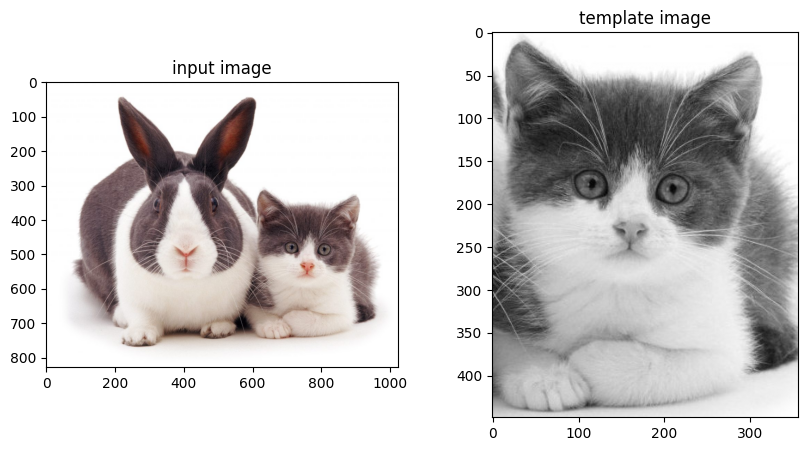

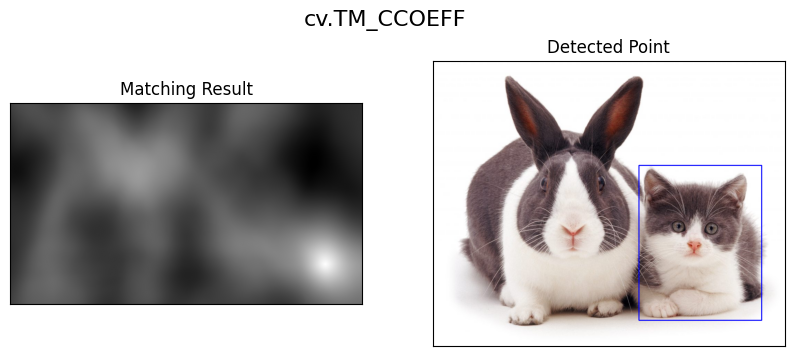

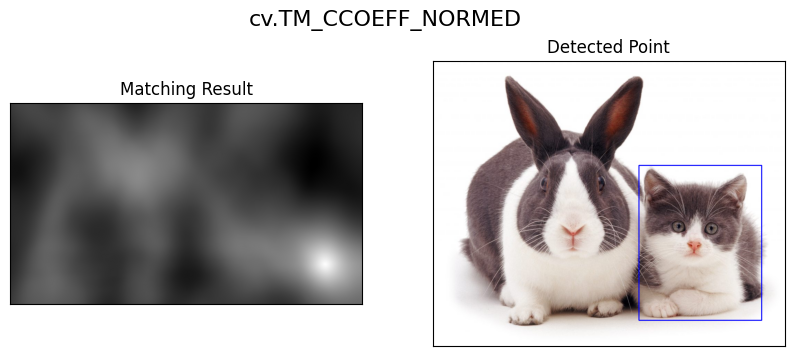

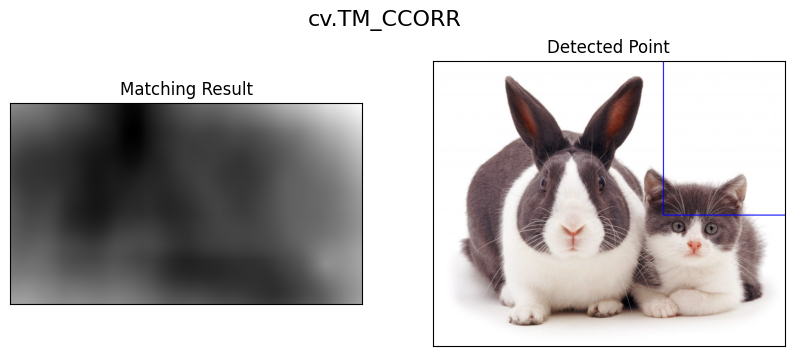

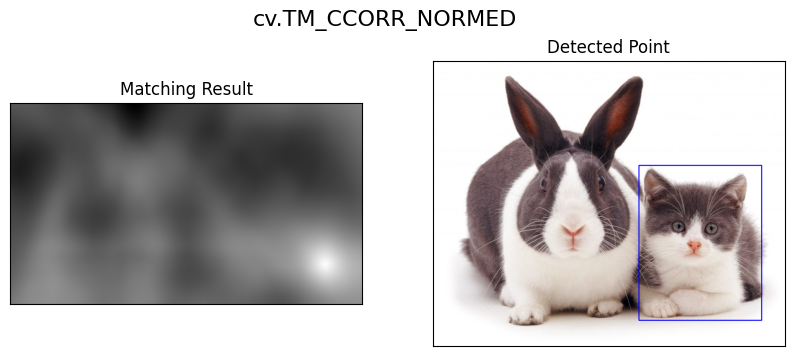

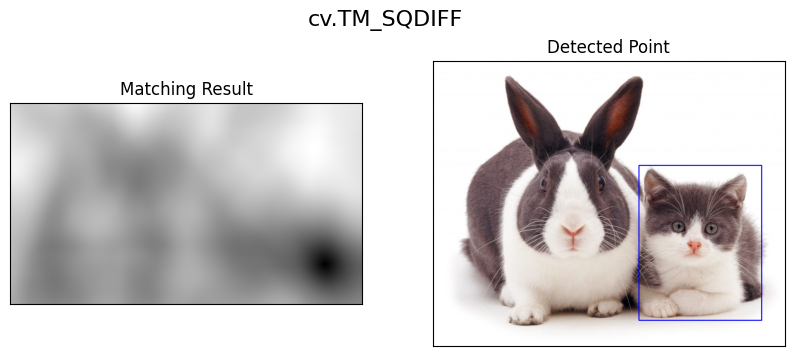

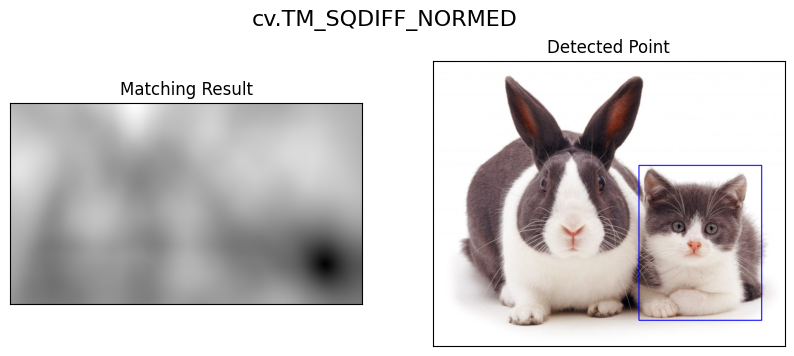

In [3]:
# Path disesuaikan dengan folder di drive
img_rgb = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cat2_templatejpg.jpg', 0)
w, h = template.shape[::-1]

# Menampilkan gambar awal
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB)), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    img = img_rgb.copy()
    method = eval(meth)

    # Apply template Matching
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img, top_left, bottom_right, (255, 0, 0), 2)

    plt.figure(figsize=(10, 4))
    plt.suptitle(meth, fontsize=16)
    plt.subplot(121), plt.imshow(res, cmap='gray'), plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.show()
